# **Lab 4**<br>

The purpose of today's lab is to obtain a practical understanding of how to visualize the Frequency domain representation of a signal and what we can understand from it. Also, we will be implementing some digital filters and see them in action.

Execute the following cell to load the sample audio:

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

from scipy.io.wavfile import read, write
from scipy.fftpack import fft, ifft
from scipy.fftpack import fftfreq
from IPython.display import Audio

Fs, x = read('StarWars3_L5.wav')
main_audio=x
N = len(x)
print('Sample count: ', N)
print('Sampling freq: ', Fs)
Audio(x, rate=Fs)

Sample count:  66150
Sampling freq:  22050


We can visualize the time domain amplitudes as follows:

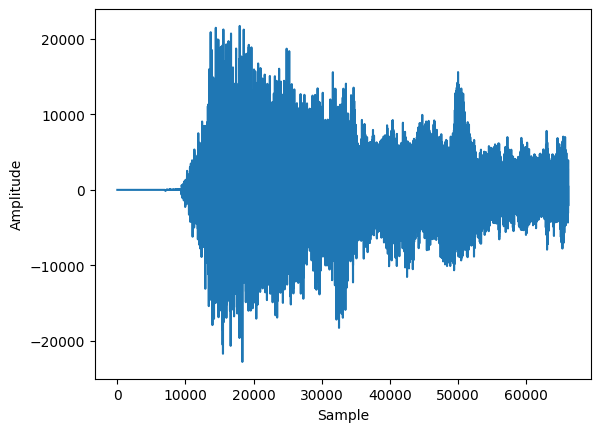

In [ ]:
plt.figure
plt.plot(x)
plt.xlabel('Sample')
plt.ylabel('Amplitude')
plt.show()

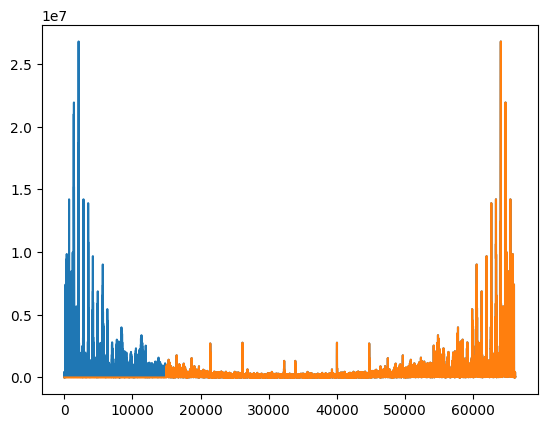

In [ ]:
X = fft(x)
plt.plot(np.abs(X))
X[0:15000] = 0
plt.plot(np.abs(X))

/usr/local/lib/python3.12/dist-packages/IPython/lib/display.py:159: ComplexWarning: Casting complex values to real discards the imaginary part
  data = np.array(data, dtype=float)
/usr/local/lib/python3.12/dist-packages/matplotlib/cbook.py:1709: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/usr/local/lib/python3.12/dist-packages/matplotlib/cbook.py:1345: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


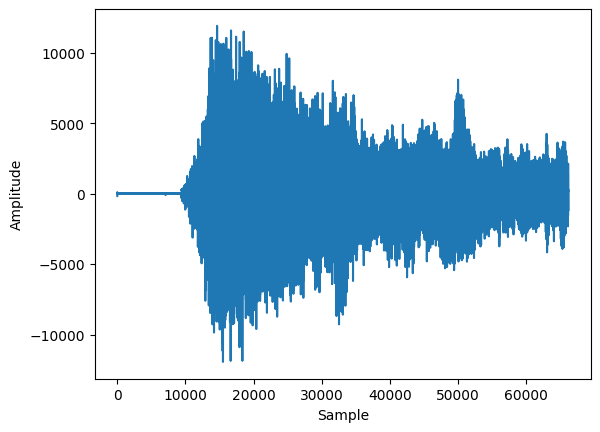

In [ ]:
x_new = ifft(X)

Audio(x_new, rate=Fs)
plt.figure
plt.plot(x_new)
plt.xlabel('Sample')
plt.ylabel('Amplitude')
plt.show()

##Task 1
Write a function named lowPass() that takes the time domain input signal $x$ and the cutoff frequency $f$ and returns the output signal $y$ where all the frequencies above $f$ are removed.

In [ ]:
def lowPass(x, f):
  f = (Fs/2) * f
  #your code here
  X = fft(x)
  n = len(x)

  freqs = fftfreq(n, 1/Fs)
  for i in range(n):
    if(abs(freqs[i]) > f):
      X[i] = 0


  return ifft(X)

For the previous audio sample, apply your implemented low pass filter on this audio with a cutoff frequency of 15000. Plot the frequency response of the filtered audio sample and play the filtered audio.

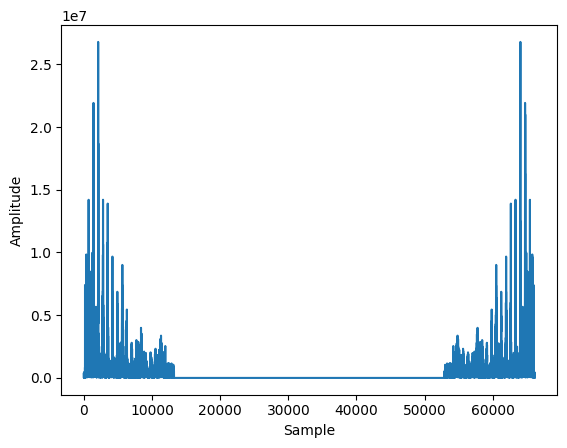

In [ ]:
#Your code here
f = 0.4
x_new = lowPass(x, f)

plt.figure
plt.plot(abs(fft(x_new)))
plt.xlabel('Sample')
plt.ylabel('Amplitude')
plt.show()


##Task 2
Write a function named highPass() that takes the time domain input signal $x$ and the cutoff frequency $f$ and returns the output signal $y$ where all the frequencies below $f$ are removed.


In [ ]:
def highPass(x, f):
  #your code here
  X = fft(x)
  n = len(X)

  high_pass_segment = int(f * (n/2))
  X[:high_pass_segment] = 0
  X[n-high_pass_segment:] = 0

  return X


For the previous audio sample, apply your implemented high pass filter on this audio with a cutoff frequency of 5000. Plot the frequency response of the filtered audio sample and play the filtered audio.

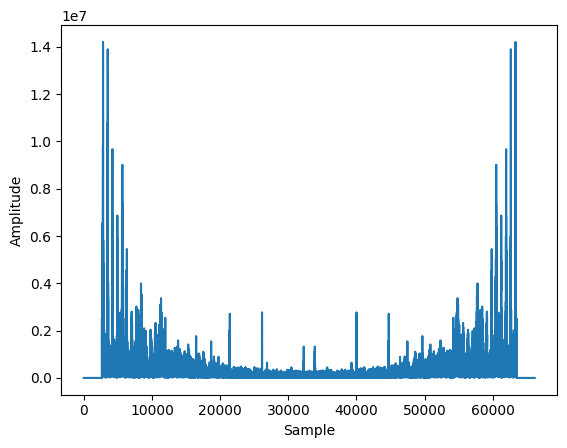

In [ ]:
#Your code here
f = 0.08
x_new = highPass(x, f)

plt.figure
plt.plot(abs(x_new))
plt.xlabel('Sample')
plt.ylabel('Amplitude')
plt.show()


##Task 3
Now write a function named bandPass() that takes the time domain input signal $x$ and the cutoff frequencies $f_{low}$ and $f_{high}$ and returns the output signal $y$ where all the frequencies below $f_{low}$ and above $f_{high}$ are removed.

In [ ]:
def bandPass(x, f_low, f_high):
  x1 = lowPass(x, f_high)
  x_new = ifft(x1)
  x2 = highPass(x_new, f_low)
  return x2

For the previous audio sample, apply your implemented band pass filter on this audio and only pass the frequencies between 5000 and 15000. Plot the frequency response of the filtered audio sample and play the filtered audio.

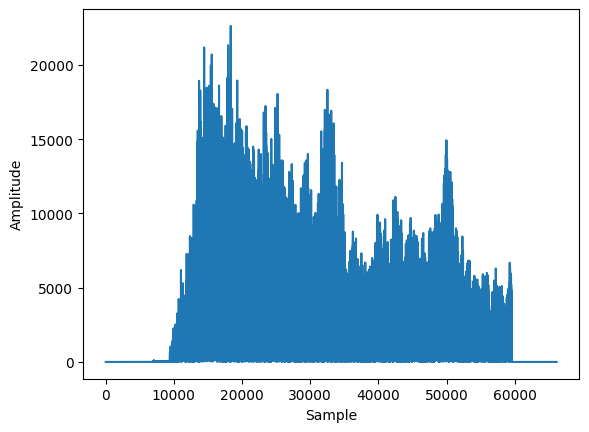

In [ ]:
#Your code here
f_low = 0.2
f_high = 0.4
x_new = bandPass(x, f_low, f_high)

plt.figure
plt.plot(abs(x_new))
plt.xlabel('Sample')
plt.ylabel('Amplitude')
plt.show()


##Task 4
Now write a function that takes an input signal and a noise level, $l$, and noise rate, $r$, as parameters and returns the input signal after corrupting it with noise. Noise level is considered as a fraction of the peak signal value and noise rate is considered as the probability by which a particular sample will be affected by noise. Both noise level and noise rate are in the range of $0-1$.

In [ ]:
def addRandomNoise(x, l, r):
  #your code here
  peak_val = np.max(x)
  noise_level = peak_val * l

  for i in range(len(x)):
    if np.random.rand() < r:
      x[i] += np.random.rand() * noise_level
  return x


For the previous audio sample, apply your implemented noise function with a noise level of $0.05$ and a noise rate of 0.5. Plot the noisy audio.

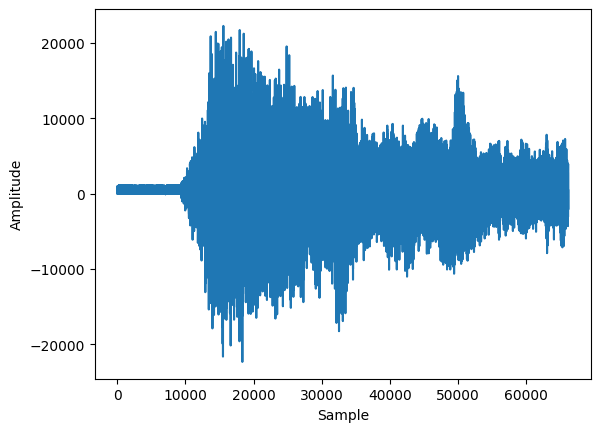

In [ ]:
#Your code here
l = 0.05
r = 0.5
corrupted_audio = addRandomNoise(main_audio, l, r)

plt.figure
plt.plot(corrupted_audio)
plt.xlabel('Sample')
plt.ylabel('Amplitude')
plt.show()

Audio(corrupted_audio, rate=Fs)

##Task 5
Write a function named MAF() that takes an input signal $x$ and a filter size $n$ and returns a filtered output signal after convolving the input with an appropriate filter kernel. The function should internally generate the filter kernel based on the size parameter. Note that the averaging mechanism should be symmetric.


In [ ]:
def convInputSide(x, h):
  y = np.zeros(len(x) + len(h) - 1)
  for i in range(len(y)):
    for j in range(len(h)):
      if 0 <= i - j < len(x):
        y[i] += h[j] * x[i - j]
  return y

def MAF(x, n):
  #your code here
  h = np.ones(n) / n
  return convInputSide(x, h)

Apply the MAF function on the previously corrupted audio and test different filter sizes to find which one produces an output that most closely resembles the original audio. Use subplot to show the output after applying filters of different sizes.

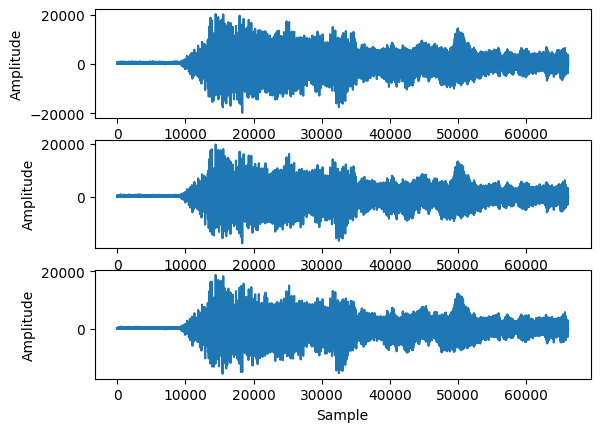

In [ ]:
#Your code here
fixed_audio1 = MAF(corrupted_audio, 3)
fixed_audio2 = MAF(corrupted_audio, 5)
fixed_audio3 = MAF(corrupted_audio, 7)

plt.figure
plt.subplot(3, 1, 1)
plt.plot(fixed_audio1)
plt.xlabel('Sample')
plt.ylabel('Amplitude')
plt.subplot(3, 1, 2)
plt.plot(fixed_audio2)
plt.xlabel('Sample')
plt.ylabel('Amplitude')
plt.subplot(3, 1, 3)
plt.plot(fixed_audio3)
plt.xlabel('Sample')
plt.ylabel('Amplitude')
plt.show()

In [ ]:
Audio(fixed_audio1, rate=Fs)

In [ ]:
Audio(fixed_audio2, rate=Fs)

In [ ]:
Audio(fixed_audio3, rate=Fs)

##Task 6
Write another function MAF_optimized() that achieves the same filtering effect without performing convolution.

*Hint: Use Recursion

In [ ]:
def MAF_optimized(x, n):
  #your code here
  y = np.zeros(len(x))
  cumsum = 0.0

  for i in range(len(x)):
    cumsum = cumsum + x[i]
    if i<n:
      y[i] = cumsum / (i+1)
    else:
      cumsum -= x[i-n]
      y[i] = cumsum / n

  #print(y)
  return y

In [ ]:
print(np.sum(corrupted_audio[0:3]))

0


Apply both MAF() and MAF_optimized() and plot the difference in time needed to apply the filter for different sizes ranging from $3$ to $99$ (using odd sizes for symmetric averaging).

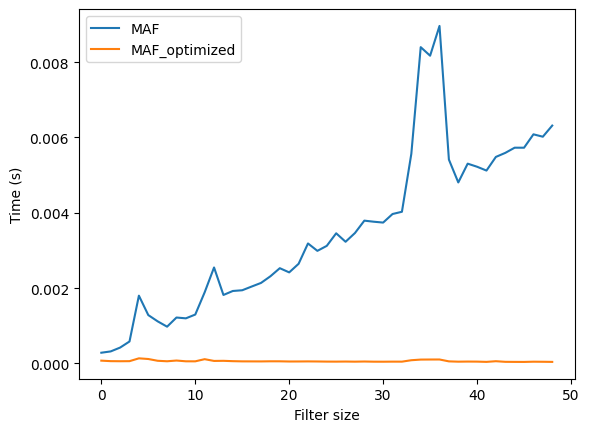

In [ ]:
#Your code here
import time

time_diff_MAF = []
time_diff_MAF_optimized = []

corrupted_audio_short = corrupted_audio[:100]

window_sizes = list(range(3, 100, 2))

for i in window_sizes:
  start_time = time.time()
  fixed_audio1 = MAF(corrupted_audio_short, i)
  end_time = time.time()
  time_diff_MAF.append(end_time - start_time)

  start_time = time.time()
  fixed_audio2 = MAF_optimized(corrupted_audio_short, i)
  end_time = time.time()
  time_diff_MAF_optimized.append(end_time - start_time)

plt.figure
plt.plot(time_diff_MAF)
plt.plot(time_diff_MAF_optimized)
plt.xlabel('Filter size')
plt.ylabel('Time (s)')
plt.legend(['MAF', 'MAF_optimized'])
plt.show()